# Лабораторная работа №3
# Головачёв Кирилл Евгеньевич Б9124-01.03.02ИИ
## Исследование архитектуры информационно-поисковой системы на примере поиска по коллекции документов

В работе строится мини-поисковая система на Python: коллекция документов → предварительная обработка → инвертированный индекс → поисковые запросы (AND / OR) → обновление индекса → схема архитектуры.

**Темы:** информационные технологии (Д1–Д4) и кулинария (Д5–Д8). Слова «поиск», «система», «запрос», «рецепт», «блюдо», «соль» намеренно встречаются в нескольких документах.

**Морфология:** используются точные словоформы (без стемминга и лемматизации), поэтому тексты подобраны так, чтобы ключевые слова повторялись в одной и той же форме.

# Установка библиотек и их импорт

In [1]:
!pip install pandas matplotlib

In [2]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams["font.family"] = "DejaVu Sans"   # шрифт с поддержкой кириллицы
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

## Шаг 1. Коллекция документов

8 документов по 4 предложения, две темы. Идентификаторы: Д1 - Д8.

In [3]:
DOCS = {
    # Тема 1: информационные технологии
    "Д1": "Поисковая система хранит коллекцию текстов. Каждый документ получает уникальный номер. "
          "Система читает документ и выделяет слова. Эти слова попадают в индекс.",
    "Д2": "Индекс — это таблица, в которой каждое слово связано со списком номеров. "
          "Поиск использует индекс вместо чтения всех текстов. Индекс ускоряет поиск. "
          "Система обновляет индекс, когда появляется новый документ.",
    "Д3": "Пользователь вводит запрос в поисковую систему. "
          "Система обрабатывает запрос так же, как документ: приводит слова к нижнему регистру и убирает знаки. "
          "Затем система находит слова запроса в таблице. Результат — документ или список документов.",
    "Д4": "Поиск по индексу работает быстрее, чем чтение всех текстов подряд. "
          "При последовательном просмотре система проверяет каждый документ. "
          "Индекс сразу показывает нужный документ. Это важно для большой коллекции.",
    # Тема 2: кулинария
    "Д5": "Рецепт борща начинается с бульона. В бульон добавляют свёклу, капусту и картофель. "
          "Соль кладут в конце. Готовое блюдо подают со сметаной.",
    "Д6": "Рецепт пасты очень прост. Воду доводят до кипения, затем в воду добавляют соль. "
          "Готовая паста смешивается с соусом. Это быстрое блюдо.",
    "Д7": "Повар ищет подходящий рецепт в книге. Каждый рецепт содержит список продуктов. "
          "Этот список помогает не забыть соль и воду. Хороший поиск экономит время.",
    "Д8": "Блюдо из овощей готовится быстро. Овощи режут и кладут в воду. "
          "В конце добавляют соль и подают горячее блюдо. Каждый рецепт можно изменить.",
}

def sent_count(text):
    return len(re.findall(r"[.!?]", text)) # по сути кол-во знаков конца предложения в тексте

df_docs = pd.DataFrame({
    "ID": list(DOCS),
    "Тема": ["IT"] * 4 + ["Кулинария"] * 4,
    "Предложений": [sent_count(t) for t in DOCS.values()],
    "Текст": list(DOCS.values()),
})
df_docs

,ID,Тема,Предложений,Текст
0,Д1,IT,4,Поисковая система хранит коллекцию текстов. Каждый документ получает уникальный номер. Система читает документ и выделяет слова. Эти слова попадают в индекс.
1,Д2,IT,4,"Индекс — это таблица, в которой каждое слово связано со списком номеров. Поиск использует индекс вместо чтения всех текстов. Индекс ускоряет поиск. Система обновляет индекс, когда появляется новый документ."
2,Д3,IT,4,"Пользователь вводит запрос в поисковую систему. Система обрабатывает запрос так же, как документ: приводит слова к нижнему регистру и убирает знаки. Затем система находит слова запроса в таблице. Результат — документ или список документов."
3,Д4,IT,4,"Поиск по индексу работает быстрее, чем чтение всех текстов подряд. При последовательном просмотре система проверяет каждый документ. Индекс сразу показывает нужный документ. Это важно для большой коллекции."
4,Д5,Кулинария,4,"Рецепт борща начинается с бульона. В бульон добавляют свёклу, капусту и картофель. Соль кладут в конце. Готовое блюдо подают со сметаной."
5,Д6,Кулинария,4,"Рецепт пасты очень прост. Воду доводят до кипения, затем в воду добавляют соль. Готовая паста смешивается с соусом. Это быстрое блюдо."
6,Д7,Кулинария,4,Повар ищет подходящий рецепт в книге. Каждый рецепт содержит список продуктов. Этот список помогает не забыть соль и воду. Хороший поиск экономит время.
7,Д8,Кулинария,4,Блюдо из овощей готовится быстро. Овощи режут и кладут в воду. В конце добавляют соль и подают горячее блюдо. Каждый рецепт можно изменить.


## Шаг 2. Предварительная обработка

Этапы: приведение к нижнему регистру → удаление знаков препинания → разделение на слова → удаление стоп-слов.

*Почему именно эти стоп-слова?* Предлоги, союзы, частицы и местоимения («в», «и», «с», «по», «это», «как», «когда»…) выполняют грамматическую функцию и не несут смысловой нагрузки. Они встречаются почти везде, поэтому по ним нельзя отличить один документ от другого: запрос «в» вернул бы всю коллекцию. Слово «каждый» — местоимение, которое встречается в документах обеих тем  и тоже не помогает различать их. Исключение таких слов уменьшает размер индекса и убирает шум из результатов.

In [4]:
STOP_WORDS = {
    "в": "предлог",
    "и": "союз",
    "с": "предлог",
    "со": "предлог",
    "по": "предлог",
    "при": "предлог",
    "из": "предлог",
    "к": "предлог",
    "или": "союз",
    "как": "союз/наречие",
    "так": "наречие/частица",
    "же": "частица",
    "чем": "союз",
    "когда": "союз",
    "затем": "служебное наречие",
    "это": "местоимение/частица",
    "всех": "местоимение",
    "каждый": "местоимение",
    "не": "частица",
}

def tokenize(text):
    text = text.lower() # приведение к нижнему регистру
    text = re.sub(r"[^\w\s]|_", " ", text) # замена знаков препинания на пробелы (всё что не является буквами, цифрами или пробелами)
    return text.split() # разбиение на слова по пробелам

def preprocess(text):
    return [w for w in tokenize(text) if w not in STOP_WORDS] # токенезация и удаление стоп-слов

rows = []
for w, kind in STOP_WORDS.items():
    n = sum(w in tokenize(t) for t in DOCS.values())
    rows.append({"Стоп-слово": w, "Часть речи": kind, "Документов (из 8)": n})
pd.DataFrame(rows).sort_values("Документов (из 8)", ascending=False).reset_index(drop=True)

,Стоп-слово,Часть речи,Документов (из 8)
0,в,предлог,7
1,и,союз,5
2,каждый,местоимение,4
3,это,местоимение/частица,3
4,с,предлог,2
5,со,предлог,2
6,затем,служебное наречие,2
7,всех,местоимение,2
8,по,предлог,1
9,при,предлог,1


In [5]:
sample = DOCS["Д3"]
print("ДО обработки:")
print(" ", sample)
print("\n После приведения к нижнему регистру и удаления знаков препинания:")
print(" ", " ".join(tokenize(sample)))
print("\n После разбиения на слова (токены):")
print(" ", tokenize(sample))
print("\n После удаления стоп-слов:")
print(" ", preprocess(sample))

ДО обработки:
  Пользователь вводит запрос в поисковую систему. Система обрабатывает запрос так же, как документ: приводит слова к нижнему регистру и убирает знаки. Затем система находит слова запроса в таблице. Результат — документ или список документов.

 После приведения к нижнему регистру и удаления знаков препинания:
  пользователь вводит запрос в поисковую систему система обрабатывает запрос так же как документ приводит слова к нижнему регистру и убирает знаки затем система находит слова запроса в таблице результат документ или список документов

 После разбиения на слова (токены):
  ['пользователь', 'вводит', 'запрос', 'в', 'поисковую', 'систему', 'система', 'обрабатывает', 'запрос', 'так', 'же', 'как', 'документ', 'приводит', 'слова', 'к', 'нижнему', 'регистру', 'и', 'убирает', 'знаки', 'затем', 'система', 'находит', 'слова', 'запроса', 'в', 'таблице', 'результат', 'документ', 'или', 'список', 'документов']

 После удаления стоп-слов:
  ['пользователь', 'вводит', 'запрос', 'пои

## Шаг 3. Инвертированный индекс

Индекс строится для 17 содержательных слов. Для каждого слова хранится множество идентификаторов документов, где оно встречается.

In [6]:
VOCAB = [
    "система", "документ", "текстов", "индекс", "поиск", "слова", "список", "запрос",   # IT
    "рецепт", "соль", "блюдо", "воду", "добавляют", "подают", "кладут", "конце", "овощи",  # кулинария
]

def doc_key(d):
    return int(d[1:]) # убираем букву "Д" и сортируем по числу

def build_index(docs, vocab):
    index = {w: set() for w in vocab} # создаём словарь, где ключи — слова из словаря, а значения — пустые множества
    for doc_id, text in docs.items():
        for w in preprocess(text):
            if w in index:
                index[w].add(doc_id)
    return index

INDEX = build_index(DOCS, VOCAB)

def index_table(index):
    return pd.DataFrame(
        [{"Слово": w, "Идентификаторы документов": ", ".join(sorted(ids, key=doc_key)),
          "Кол-во документов": len(ids)}
         for w, ids in sorted(index.items())]
    )

index_table(INDEX)

,Слово,Идентификаторы документов,Кол-во документов
0,блюдо,"Д5, Д6, Д8",3
1,воду,"Д6, Д7, Д8",3
2,добавляют,"Д5, Д6, Д8",3
3,документ,"Д1, Д2, Д3, Д4",4
4,запрос,Д3,1
5,индекс,"Д1, Д2, Д4",3
6,кладут,"Д5, Д8",2
7,конце,"Д5, Д8",2
8,овощи,Д8,1
9,подают,"Д5, Д8",2


## Шаг 4. Поисковые запросы

Запрос проходит ту же предобработку, что и документы. Затем из индекса извлекаются списки документов по каждому слову, и они объединяются:
- *AND* — пересечение списков (содержит все слова);
- *OR* — объединение списков (содержит хотя бы одно слово).

Запросы:
1. *индекс* — однословный;
2. *соль* — однословный;
3. *поиск система* — двухсловный (AND и OR);
4. *блюдо воду* — двухсловный (AND и OR).

In [7]:
def postings(index, word):
    return index.get(word, set())

def fmt(ids):
    return "{" + ", ".join(sorted(ids, key=doc_key)) + "}" if ids else "{} (пусто)"

def search(index, query, mode="AND", verbose=True):
    words = preprocess(query) # Предобработка запроса: токенизация и удаление стоп-слов
    lists = [postings(index, w) for w in words] # Для каждого слова из запроса получаем список документов из индекса

    if verbose: # Выводим информацию о запросе и списках документов для каждого слова ( по умолчанию включено )
        print(f"Запрос: «{query}»   режим: {mode if len(words) > 1 else '— (одно слово)'}")
        for w, ids in zip(words, lists):
            print(f"  из индекса: {w!r:12} -> {fmt(ids)}")

    if not lists: # если список списков пустой (нет слов в запросе), то результат пустой
        result = set()
    elif mode == "AND": # если режим поиска "AND", то пересечение множеств
        result = set.intersection(*lists)
    else: # если режим поиска "OR", то объединение множеств
        result = set.union(*lists)

    if verbose: # ывводим информацию о результатах поиска ( по умолчанию включено )
        if len(words) > 1:
            op = "∩" if mode == "AND" else "∪"
            print(f"  операция: {f' {op} '.join(fmt(l) for l in lists)} = {fmt(result)}")
        print(f"  РЕЗУЛЬТАТ: {fmt(result)}")
    return result

def show_result(result):
    for d in sorted(result, key=doc_key):
        print(f"[{d}] {DOCS[d]}")

# Запрос 1 (одно слово)
r = search(INDEX, "индекс")
show_result(r)

Запрос: «индекс»   режим: — (одно слово)
  из индекса: 'индекс'     -> {Д1, Д2, Д4}
  РЕЗУЛЬТАТ: {Д1, Д2, Д4}
[Д1] Поисковая система хранит коллекцию текстов. Каждый документ получает уникальный номер. Система читает документ и выделяет слова. Эти слова попадают в индекс.
[Д2] Индекс — это таблица, в которой каждое слово связано со списком номеров. Поиск использует индекс вместо чтения всех текстов. Индекс ускоряет поиск. Система обновляет индекс, когда появляется новый документ.
[Д4] Поиск по индексу работает быстрее, чем чтение всех текстов подряд. При последовательном просмотре система проверяет каждый документ. Индекс сразу показывает нужный документ. Это важно для большой коллекции.


In [8]:
#  Запрос 2 (одно слово)
r = search(INDEX, "соль")
show_result(r)

Запрос: «соль»   режим: — (одно слово)
  из индекса: 'соль'       -> {Д5, Д6, Д7, Д8}
  РЕЗУЛЬТАТ: {Д5, Д6, Д7, Д8}
[Д5] Рецепт борща начинается с бульона. В бульон добавляют свёклу, капусту и картофель. Соль кладут в конце. Готовое блюдо подают со сметаной.
[Д6] Рецепт пасты очень прост. Воду доводят до кипения, затем в воду добавляют соль. Готовая паста смешивается с соусом. Это быстрое блюдо.
[Д7] Повар ищет подходящий рецепт в книге. Каждый рецепт содержит список продуктов. Этот список помогает не забыть соль и воду. Хороший поиск экономит время.
[Д8] Блюдо из овощей готовится быстро. Овощи режут и кладут в воду. В конце добавляют соль и подают горячее блюдо. Каждый рецепт можно изменить.


In [9]:
#Запрос 3 (два слова): AND и OR
print("=== AND ===")
r = search(INDEX, "поиск система", "AND")
show_result(r)
print("=== OR ===")
r = search(INDEX, "поиск система", "OR")
show_result(r)

=== AND ===
Запрос: «поиск система»   режим: AND
  из индекса: 'поиск'      -> {Д2, Д4, Д7}
  из индекса: 'система'    -> {Д1, Д2, Д3, Д4}
  операция: {Д2, Д4, Д7} ∩ {Д1, Д2, Д3, Д4} = {Д2, Д4}
  РЕЗУЛЬТАТ: {Д2, Д4}
[Д2] Индекс — это таблица, в которой каждое слово связано со списком номеров. Поиск использует индекс вместо чтения всех текстов. Индекс ускоряет поиск. Система обновляет индекс, когда появляется новый документ.
[Д4] Поиск по индексу работает быстрее, чем чтение всех текстов подряд. При последовательном просмотре система проверяет каждый документ. Индекс сразу показывает нужный документ. Это важно для большой коллекции.
=== OR ===
Запрос: «поиск система»   режим: OR
  из индекса: 'поиск'      -> {Д2, Д4, Д7}
  из индекса: 'система'    -> {Д1, Д2, Д3, Д4}
  операция: {Д2, Д4, Д7} ∪ {Д1, Д2, Д3, Д4} = {Д1, Д2, Д3, Д4, Д7}
  РЕЗУЛЬТАТ: {Д1, Д2, Д3, Д4, Д7}
[Д1] Поисковая система хранит коллекцию текстов. Каждый документ получает уникальный номер. Система читает документ и выде

In [10]:
# --- Запрос 4 (два слова): AND и OR
print("=== AND ===")
r = search(INDEX, "блюдо воду", "AND"); show_result(r)
print("=== OR ===")
r = search(INDEX, "блюдо воду", "OR");  show_result(r)

=== AND ===
Запрос: «блюдо воду»   режим: AND
  из индекса: 'блюдо'      -> {Д5, Д6, Д8}
  из индекса: 'воду'       -> {Д6, Д7, Д8}
  операция: {Д5, Д6, Д8} ∩ {Д6, Д7, Д8} = {Д6, Д8}
  РЕЗУЛЬТАТ: {Д6, Д8}
[Д6] Рецепт пасты очень прост. Воду доводят до кипения, затем в воду добавляют соль. Готовая паста смешивается с соусом. Это быстрое блюдо.
[Д8] Блюдо из овощей готовится быстро. Овощи режут и кладут в воду. В конце добавляют соль и подают горячее блюдо. Каждый рецепт можно изменить.
=== OR ===
Запрос: «блюдо воду»   режим: OR
  из индекса: 'блюдо'      -> {Д5, Д6, Д8}
  из индекса: 'воду'       -> {Д6, Д7, Д8}
  операция: {Д5, Д6, Д8} ∪ {Д6, Д7, Д8} = {Д5, Д6, Д7, Д8}
  РЕЗУЛЬТАТ: {Д5, Д6, Д7, Д8}
[Д5] Рецепт борща начинается с бульона. В бульон добавляют свёклу, капусту и картофель. Соль кладут в конце. Готовое блюдо подают со сметаной.
[Д6] Рецепт пасты очень прост. Воду доводят до кипения, затем в воду добавляют соль. Готовая паста смешивается с соусом. Это быстрое блюдо.
[Д7] Пов

## Шаг 5. Добавление нового документа

Новый документ *Д9* содержит:
- *уже проиндексированные слова*: система, поиск, запрос, документ, рецепт, блюдо, добавляют, соль — для них в существующие строки индекса нужно дописать Д9.
- *новые слова*: «кулинарная», «повару», «сыр» — для них нужно создать новые строки индекса.

In [11]:
NEW_ID = "Д9"
NEW_TEXT = ("Кулинарная система помогает повару выполнить поиск. "
            "Повару достаточно ввести запрос и получить рецепт. "
            "Каждый рецепт хранится как документ. В блюдо добавляют сыр и соль.")
NEW_TERMS = ["кулинарная", "повару", "сыр"]

print("Токены нового документа после предобработки:")
print(preprocess(NEW_TEXT))

INDEX_BEFORE = {w: set(ids) for w, ids in INDEX.items()}
before_and = search(INDEX, "поиск система", "AND", verbose=False)
before_or  = search(INDEX, "поиск система", "OR",  verbose=False)

def add_document(index, doc_id, text, new_terms=()):
    """Добавляет документ в коллекцию и обновляет индекс. Возвращает (изменённые, новые) слова."""
    DOCS[doc_id] = text # Добавляем новый документ в общий словарь документов
    added, changed = [], []
    # 1) новые термины: создаём запись и првоверяем все старые документы
    for term in new_terms:
        if term not in index:
            index[term] = set()

            # Строка ниже для информации
            added.append(term)

            for d, t in DOCS.items():
                if d != doc_id and term in preprocess(t):
                    index[term].add(d) # Встретилось в старых документах, добавляем их идентификаторы в индекс
    # 2) дописываем идентификатор нового документа в записи его слов
    for w in set(preprocess(text)):
        if w in index and doc_id not in index[w]: # если слово уже есть в индексе и идентификатор документа ещё не добавлен
            index[w].add(doc_id)

            # Строки ниже для информации
            if w not in added:
                changed.append(w)

    return sorted(changed), sorted(added)

changed, added = add_document(INDEX, NEW_ID, NEW_TEXT, NEW_TERMS)
print("\nИзменены существующие записи:", changed)
print("Добавлены новые записи:     ", added)

Токены нового документа после предобработки:
['кулинарная', 'система', 'помогает', 'повару', 'выполнить', 'поиск', 'повару', 'достаточно', 'ввести', 'запрос', 'получить', 'рецепт', 'рецепт', 'хранится', 'документ', 'блюдо', 'добавляют', 'сыр', 'соль']

Изменены существующие записи: ['блюдо', 'добавляют', 'документ', 'запрос', 'поиск', 'рецепт', 'система', 'соль']
Добавлены новые записи:      ['кулинарная', 'повару', 'сыр']


In [12]:
rows = []
for w in sorted(set(INDEX) ):
    old = INDEX_BEFORE.get(w)
    new = INDEX[w]
    if old is None:
        rows.append({"Слово": w, "Тип": "добавлена новая запись", "Было": "—",
                     "Стало": ", ".join(sorted(new, key=doc_key))})
    elif old != new:
        rows.append({"Слово": w, "Тип": "изменена запись", "Было": ", ".join(sorted(old, key=doc_key)),
                     "Стало": ", ".join(sorted(new, key=doc_key))})
pd.DataFrame(rows)

,Слово,Тип,Было,Стало
0,блюдо,изменена запись,"Д5, Д6, Д8","Д5, Д6, Д8, Д9"
1,добавляют,изменена запись,"Д5, Д6, Д8","Д5, Д6, Д8, Д9"
2,документ,изменена запись,"Д1, Д2, Д3, Д4","Д1, Д2, Д3, Д4, Д9"
3,запрос,изменена запись,Д3,"Д3, Д9"
4,кулинарная,добавлена новая запись,—,Д9
5,повару,добавлена новая запись,—,Д9
6,поиск,изменена запись,"Д2, Д4, Д7","Д2, Д4, Д7, Д9"
7,рецепт,изменена запись,"Д5, Д6, Д7, Д8","Д5, Д6, Д7, Д8, Д9"
8,система,изменена запись,"Д1, Д2, Д3, Д4","Д1, Д2, Д3, Д4, Д9"
9,соль,изменена запись,"Д5, Д6, Д7, Д8","Д5, Д6, Д7, Д8, Д9"


In [13]:
print("Повторяем запрос «поиск система» после добавления Д9 \n")
print("=== AND ===")
after_and = search(INDEX, "поиск система", "AND")
show_result(after_and)
print("=== OR ===")
after_or = search(INDEX, "поиск система", "OR")
show_result(after_or)

print("Сравнение:")
print(f"  AND: было {fmt(before_and)}  ->  стало {fmt(after_and)}   (новое: {fmt(after_and - before_and)})")
print(f"  OR : было {fmt(before_or)}  ->  стало {fmt(after_or)}   (новое: {fmt(after_or - before_or)})")

Повторяем запрос «поиск система» после добавления Д9 

=== AND ===
Запрос: «поиск система»   режим: AND
  из индекса: 'поиск'      -> {Д2, Д4, Д7, Д9}
  из индекса: 'система'    -> {Д1, Д2, Д3, Д4, Д9}
  операция: {Д2, Д4, Д7, Д9} ∩ {Д1, Д2, Д3, Д4, Д9} = {Д2, Д4, Д9}
  РЕЗУЛЬТАТ: {Д2, Д4, Д9}
[Д2] Индекс — это таблица, в которой каждое слово связано со списком номеров. Поиск использует индекс вместо чтения всех текстов. Индекс ускоряет поиск. Система обновляет индекс, когда появляется новый документ.
[Д4] Поиск по индексу работает быстрее, чем чтение всех текстов подряд. При последовательном просмотре система проверяет каждый документ. Индекс сразу показывает нужный документ. Это важно для большой коллекции.
[Д9] Кулинарная система помогает повару выполнить поиск. Повару достаточно ввести запрос и получить рецепт. Каждый рецепт хранится как документ. В блюдо добавляют сыр и соль.
=== OR ===
Запрос: «поиск система»   режим: OR
  из индекса: 'поиск'      -> {Д2, Д4, Д7, Д9}
  из индекса

**Сравнение.** До добавления Д9 результат запроса не включал этот документ. После обновления индекса Д9 появился в результатах, потому что содержит оба слова запроса — «поиск» и «система». Если бы индекс не обновили, Д9 остался бы невидимым для поиска, хотя он есть в коллекции.

## Шаг 6. Архитектура поисковой системы

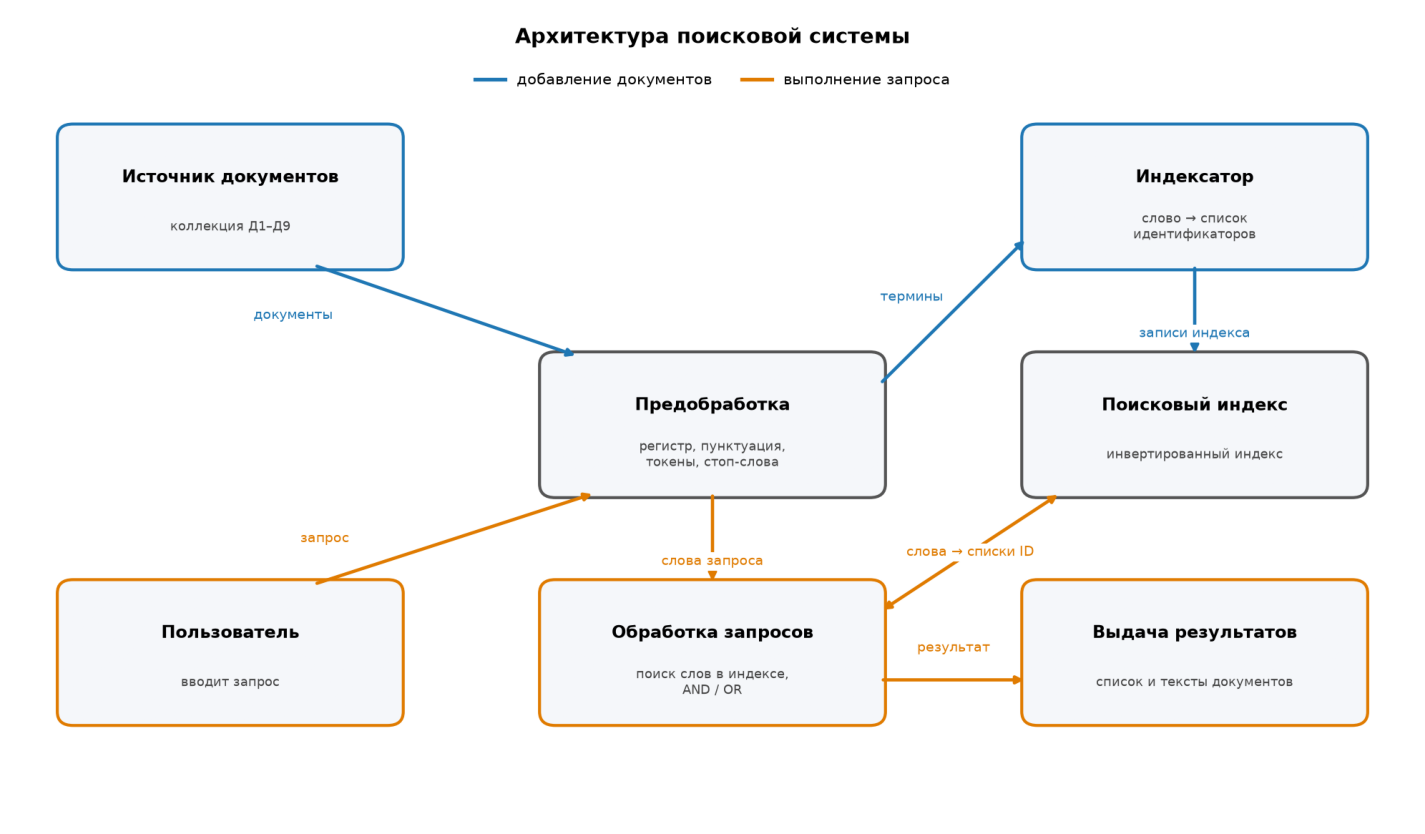

In [14]:
plt.figure(figsize=(12, 8), dpi=150)
img = plt.imread('architecture.png')
plt.imshow(img)
plt.axis('off')
plt.show()

### Назначение компонентов

| Компонент | Назначение |
|---|---|
| **Источник документов** | Хранит исходную коллекцию текстов и присваивает им уникальные идентификаторы. |
| **Предобработка** | Приводит текст к единому виду: нижний регистр, удаление знаков препинания, разбиение на слова, удаление стоп-слов. Один и тот же модуль обрабатывает и документы, и запросы, чтобы слова сравнивались в одинаковой форме. |
| **Индексатор** | Просматривает обработанные документы и для каждого слова записывает, в каких документах оно встречается. Вызывается при добавлении документа. |
| **Поисковый индекс** | Структура данных «слово → список документов», по которой выполняется поиск. |
| **Обработка запросов** | Принимает слова запроса, извлекает списки из индекса и объединяет их операциями AND (пересечение) или OR (объединение). |
| **Выдача результатов** | Формирует ответ пользователю: идентификаторы найденных документов и их полный текст. |

## Шаг 7. Вывод

Разница между поиском по индексу и последовательным просмотром.

In [15]:
def sequential_search(word):
    """Полный перебор: читаем каждый документ слово за словом."""
    found, comparisons = set(), 0
    for d, text in DOCS.items():
        for tok in tokenize(text):
            comparisons += 1
            if tok == word:
                found.add(d)
    return found, comparisons

word = "соль"
seq_result, seq_cmp = sequential_search(word)
idx_result = search(INDEX, word, verbose=False)

print(f"Запрос «{word}», коллекция из {len(DOCS)} документов")
print(f"  последовательный просмотр: {fmt(seq_result)}, сравнений слов: {seq_cmp}")
print(f"  поиск по индексу:          {fmt(idx_result)}, обращений к индексу: 1")
print("  результаты совпадают:", seq_result == idx_result)

Запрос «соль», коллекция из 9 документов
  последовательный просмотр: {Д5, Д6, Д7, Д8, Д9}, сравнений слов: 221
  поиск по индексу:          {Д5, Д6, Д7, Д8, Д9}, обращений к индексу: 1
  результаты совпадают: True


### Вывод

В работе построена модель поисковой системы из шести компонентов, и каждый из них решает свою задачу. Источник документов хранит коллекцию и идентификаторы. Предобработка приводит документы и запросы к единой форме, поэтому слова можно сравнивать между собой, а стоп-слова не засоряют индекс. Индексатор превращает набор текстов в инвертированный индекс — хеш таблицу «слово → документы».Обработка запросов извлекает из индекса готовые списки и комбинирует их операциями AND и OR, а выдача результатов возвращает пользователю найденные документы.

Поиск по индексу и последовательный просмотр. При последовательном просмотре система читает все тексты слово за словом при каждом запросе, поэтому время растёт вместе с объёмом коллекции. В эксперименте это потребовало сотни сравнений слов против одного обращения к индексу. Индекс строится заранее, один раз; затем ответ на запрос — это извлечение готового списка и простая операция над множествами. Платой за скорость становятся дополнительная память для индекса и необходимость его поддерживать.

Зачем обновлять индекс. Индекс — это копия информации о коллекции на момент построения. Сам по себе он не «видит» новые тексты: пока например Д9 не внесён в индекс, ни один запрос его не найдёт, хотя документ лежит в коллекции. После добавления документа нужно дописать его идентификатор в записи уже известных слов и создать записи для новых слов. На шаге 5 это привело к тому, что результат запроса «поиск система» изменился: в него вошёл Д9.